# Phase 7: NeSy retrieval (offline, $0)

**Goal:** the RAG arm (14) lost rules. Vector search found 71% of the rules the graph gives, and 24 of its 28 violations broke C3, the rule it missed most. Here I test a **neurosymbolic retriever**: neural search finds a few rules, and the graph adds the rest.

**How it works (no new agent runs):** I reuse the 440 retrievals logged by notebook 14 (`results_gemini_rag/trial_*/rag.jsonl`).

| Method | Neural part | Symbolic part |
|---|---|---|
| Vector RAG (14) | top bullets by embedding similarity | none |
| **NeSy** | the same top bullets (seeds) | score each graph action by its seed rules; keep the best one; follow action → tool → sibling actions; return their graph rules |
| NeSy loose | the same seeds | every action any seed belongs to |
| Graph (semi-deep, 08) | none | rules of the action named by the tool call |

Global rules (G1–G5) are ignored when picking the action, because they belong to many actions. NeSy never uses the tool name to choose rules; the graph decides.

**Metrics:** recall (share of the graph's rules for the action that were returned), checks with all rules found, precision (share of returned rules that were needed), rules returned.

**Run first:** 08 (`graph_text.py`) and 14 (`rag_text.py` and the logs). **Runtime:** CPU, about 1 minute. **Cost:** $0, no API calls, no model download.

**Result:** recall 71% → 96%, C3 found in 173 of 173 cancellation checks (vector: 62). See the Summary at the end.

**Limit:** this measures retrieval only. It does not show how the agent would act with NeSy rules; that needs a new run (about $22).

| cell | what | why |
|---|---|---|
| 1 | mount Drive | the logs from 14 are on Drive |
| 2 | paths + file check | stop early if 08 or 14 was not run |
| 3 | save `nesy.py` | the NeSy retriever |
| 4 | main table | vector vs NeSy vs graph, same seeds |
| 5 | per tool + C3 | where the graph helps, where it picks the wrong action |
| 6 | figure | `figures/nesy_recall.png` for the report and slides |

In [8]:
# Why: results and code live on Google Drive.
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
# Why: one path and one table style for the whole notebook; check the files from 08 and 14 exist.
import os, sys, json, glob, importlib
import pandas as pd
from IPython.display import display
ROOT = "/content/drive/MyDrive/cmsc691-10-project2"
sys.path.insert(0, ROOT); os.chdir(ROOT)
need = ["graph_text.py", "rag_text.py", "airline_policy_graph.json"]
missing = [f for f in need if not os.path.exists(f)] + ([] if glob.glob("results_gemini_rag/trial_*/rag.jsonl") else ["results_gemini_rag/*/rag.jsonl"])
assert not missing, f"missing {missing}: run 08 and 14 first"
def show(df, index=False):
    st = df.style.set_properties(**{"text-align": "left"})
    display(st if index else st.hide(axis="index"))
show(pd.DataFrame({"check": ["files from 08 and 14", "RAG retrieval logs"],
                   "value": ["✅", f"{len(glob.glob('results_gemini_rag/trial_*/rag.jsonl'))} trials"]}))

check,value
files from 08 and 14,✅
RAG retrieval logs,8 trials


In [4]:
# Why: the NeSy retriever: neural seeds from the RAG logs + expansion on the policy graph.
# The file's code is in CODE below; this cell saves it into the repo and shows a one-row table.
CODE = r'''# NeSy retrieval, offline: neural seeds (the RAG arm's logged vector hits) + symbolic expansion on the policy graph.
# No tool name is used to pick rules: the graph decides which action the seeds point to.
import json, glob, re
import graph_text as gt, rag_text as rt

def action_rules(G):
    """graph action -> rule ids it uses; action -> tool (graph edge)."""
    rules = {a["action"]: set(rt.needed(gt.action_text(G, a["action"]))) for a in G["actions"]}
    tool = {a["action"]: a["tool"] for a in G["actions"]}
    return rules, tool

def ground(seeds, scores, rules, tool):
    """Symbolic step: score each action by the retrieval scores of its own (non-global) seed rules,
    keep the best action, then follow action -> tool -> sibling actions."""
    s = {}
    for r, sc in zip(seeds, scores):
        if not r or r.startswith("G"): continue
        for a, rs in rules.items():
            if r in rs: s[a] = s.get(a, 0) + sc
    if not s: return set(), []
    best = max(s, key=s.get)
    acts = [a for a in rules if tool[a] == tool[best]]
    return set().union(*(rules[a] for a in acts)), acts

def touched(seeds, rules):
    """Looser variant: union of every action any seed belongs to."""
    acts = [a for a, rs in rules.items() if any(r in rs for r in seeds if r and not r.startswith("G"))]
    return set().union(*(rules[a] for a in acts)) if acts else set(), acts

def evaluate(rows, G):
    rules, tool = action_rules(G)
    out = []
    for x in rows:
        need = set(x["needed"]); seeds = [s for s in x["sources"]]
        vec = {s for s in seeds if s}
        nesy, acts = ground(seeds, x["scores"], rules, tool)
        loose, lacts = touched(seeds, rules)
        out.append({"tool": x["tool"], "need": need, "vector": vec, "nesy": nesy, "nesy_loose": loose,
                    "graph": need, "nesy_right_action": tool.get(acts[0]) == x["tool"] if acts else False})
    return out
'''

open(f"{ROOT}/nesy.py", "w").write(CODE)
show(pd.DataFrame([{"file": "nesy.py", "lines": CODE.count(chr(10)), "saved": "✅"}]))

file,lines,saved
nesy.py,40,✅


In [5]:
# Why: the main comparison. Same seeds for vector and NeSy, so any gain comes from the graph.
import graph_text as gt, rag_text as rt, nesy
for m in (gt, rt, nesy): importlib.reload(m)
G = gt.load()
rows = [json.loads(l) for f in sorted(glob.glob(f"{ROOT}/results_gemini_rag/trial_*/rag.jsonl")) for l in open(f)]
R = nesy.evaluate(rows, G)
def metrics(k):
    rec = [len(r["need"] & r[k]) / len(r["need"]) for r in R]
    return {"recall": sum(rec) / len(R), "all rules found": sum(r["need"] <= r[k] for r in R) / len(R),
            "precision": sum(len(r["need"] & r[k]) / len(r[k]) if r[k] else 0 for r in R) / len(R),
            "rules returned": sum(len(r[k]) for r in R) / len(R)}
names = {"vector": "Vector RAG (14)", "nesy": "NeSy (vector + graph)", "nesy_loose": "NeSy loose", "graph": "Graph by tool (semi-deep)"}
T = pd.DataFrame([{"method": names[k], **metrics(k)} for k in names])
for c in ["recall", "all rules found", "precision"]: T[c] = T[c].map("{:.0%}".format)
T["rules returned"] = T["rules returned"].map("{:.1f}".format)
print(f"{len(R)} checks from the RAG arm")
show(T)
T.to_csv(f"{ROOT}/results_nesy_retrieval.csv", index=False)

440 checks from the RAG arm


method,recall,all rules found,precision,rules returned
Vector RAG (14),71%,16%,62%,4.6
NeSy (vector + graph),96%,89%,93%,4.5
NeSy loose,100%,99%,41%,11.4
Graph by tool (semi-deep),100%,100%,100%,4.2


In [6]:
# Why: where does the graph help, and where does it pick the wrong action?
D = pd.DataFrame([{"tool": r["tool"], "vector": len(r["need"] & r["vector"]) / len(r["need"]),
                   "nesy": len(r["need"] & r["nesy"]) / len(r["need"]), "right action": r["nesy_right_action"]} for r in R])
P = D.groupby("tool").agg(checks=("vector", "size"), vector=("vector", "mean"), nesy=("nesy", "mean"), right_action=("right action", "mean")).reset_index()
for c in ["vector", "nesy", "right_action"]: P[c] = P[c].map("{:.0%}".format)
show(P.rename(columns={"vector": "vector recall", "nesy": "NeSy recall", "right_action": "NeSy picked the right action"}))
c = [r for r in R if r["tool"] == "cancel_reservation"]
show(pd.DataFrame([{"rule": "C3 (no flown segment)", "cancel checks": len(c),
                    "found by vector": sum("C3" in r["vector"] for r in c), "found by NeSy": sum("C3" in r["nesy"] for r in c)}]))

tool,checks,vector recall,NeSy recall,NeSy picked the right action
book_reservation,59,43%,100%,100%
cancel_reservation,173,79%,100%,100%
update_reservation_baggages,36,64%,71%,14%
update_reservation_flights,154,80%,100%,100%
update_reservation_passengers,18,33%,67%,0%


rule,cancel checks,found by vector,found by NeSy
C3 (no flown segment),173,62,173


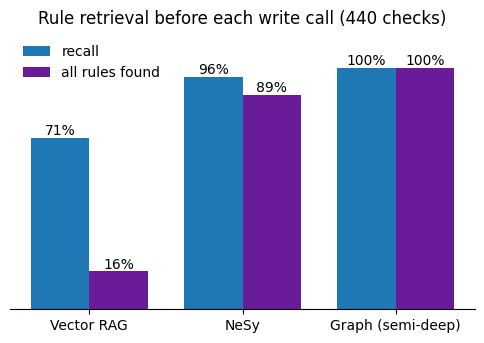

In [7]:
# Why: one figure for the report and slides.
import matplotlib.pyplot as plt
k = ["vector", "nesy", "graph"]; lab = ["Vector RAG", "NeSy", "Graph (semi-deep)"]
vals = [metrics(x)["recall"] for x in k]; full = [metrics(x)["all rules found"] for x in k]
fig, ax = plt.subplots(figsize=(6, 3.6)); w = 0.38; xs = range(len(k))
b1 = ax.bar([i - w/2 for i in xs], vals, w, label="recall", color="#1F77B4")
b2 = ax.bar([i + w/2 for i in xs], full, w, label="all rules found", color="#6A1B9A")
ax.bar_label(b1, fmt="%.0f%%", labels=[f"{v:.0%}" for v in vals]); ax.bar_label(b2, labels=[f"{v:.0%}" for v in full])
ax.set_xticks(list(xs), lab); ax.set_ylim(0, 1.15); ax.set_yticks([]); ax.legend(frameon=False, loc="upper left")
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.set_title("Rule retrieval before each write call (440 checks)")
os.makedirs(f"{ROOT}/figures", exist_ok=True); plt.savefig(f"{ROOT}/figures/nesy_recall.png", dpi=200, bbox_inches="tight"); plt.show()

## Summary

| Method | Recall | All rules found | Precision | Rules returned |
|---|---|---|---|---|
| Vector RAG (14) | 71% | 16% | 62% | 4.6 |
| **NeSy (vector + graph)** | **96%** | **89%** | **93%** | 4.5 |
| NeSy loose | 100% | 99% | 41% | 11.4 |
| Graph by tool (semi-deep) | 100% | 100% | 100% | 4.2 |

- **The graph fills the gaps.** With the same vector seeds, NeSy raises recall from 71% to 96% and returns about the same number of rules.
- **C3 is fixed.** In cancellations, vector search found C3 in 62 of 173 checks; NeSy found it in all 173. C3 is the rule behind 24 of RAG's 28 violations.
- **Where NeSy fails:** baggage and passenger changes. Their seeds point to the flight-change rule M2, so NeSy picks the wrong action (right action: 14% and 0%).
- **Loose is not better.** Taking every action a seed touches finds almost everything, but returns 2.5× more rules (precision 41%).
- **Cost:** $0, no API calls, about 1 minute.

**Takeaway:** neural search finds a few rules; the graph adds the rest. This measures retrieval only. Whether the agent then breaks fewer rules needs a new run (about $22).